<div>
<img src="wise0855_pic.jpg" width="1000"/>
</div>

# Photometry: Weather on WISE 0855, the Jupiter Next Door

For this assignment we will learn how to do aperture photometry on an astronomical source and begin estimating the error on a photometric point. The data we are working with are raw and reduced [Spitzer IRAC](https://irsa.ipac.caltech.edu/data/SPITZER/docs/irac/) images. The IRAC Channel used is IRAC2 which is sensitive to light centered at 4.5$\mu$m. The data set for this lab was published in [Esplin+2016](https://ui.adsabs.harvard.edu/abs/2016ApJ...832...58E/abstract). The author of this paper took numerous images of the same field of view over time. This field of view contains WISE 0855, a nearby, isolated brown dwarf that is cooler than Earth and two times more massive than Jupiter. We will complete aperture photometry on each image to complete a time-series photometric light curve for WISE 0855. You should read the paper to understand their scientific goals and observational strategy.

The reduced data were searched for at the [Spitzer Heritage Archive]((https://irsa.ipac.caltech.edu/applications/Spitzer/SHA/) (https://irsa.ipac.caltech.edu/applications/Spitzer/SHA/). "Lower level" or raw data files are stored in the archive as well.

In [2]:
#We will import several useful functions. We are importing numpy, matplotlib, astropy.
#glob is a function that allows you to call in multiple files at once.
#photutils is an astropy related package for doing aperture photometry on 2-d data products

import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
import glob
from photutils.aperture import CircularAperture, CircularAnnulus, aperture_photometry, ApertureStats

# Inspecting the Imaging Science Data

Look at the data within the "data" directory for this lab. Each image should contain numerous point sources of varying brightnesses. We'll pull in the header information and plot the image data for a single file. Fits files often contain both 2-D image information and metadata associated with the telescope, observing conditions, program PI, and many other parameters. When looking up archival data it is often very important to look at the header information of the fits files to understand the observing conditions.

Information on the header names and naming conventions for Spizter data can be found at these links:

https://irsa.ipac.caltech.edu/data/SPITZER/docs/irac/iracinstrumenthandbook/32/#_Toc82083673

https://irsa.ipac.caltech.edu/data/SPITZER/docs/irac/iracinstrumenthandbook/31/

In [3]:
sci_reduced_image_header = fits.getheader('data/SPITZER_I2_52667904_0001_0000_2_cbcd.fits')

sci_reduced_image_header

SIMPLE  =                    T / Fits standard                                  
BITPIX  =                  -32 / FOUR-BYTE SINGLE PRECISION FLOATING POINT      
NAXIS   =                    2 / STANDARD FITS FORMAT                           
NAXIS1  =                  256 / STANDARD FITS FORMAT                           
NAXIS2  =                  256 / STANDARD FITS FORMAT                           
ORIGIN  = 'Spitzer Science Center' / Organization generating this FITS file     
CREATOR = 'S19.2.0 '           / SW version used to create this FITS file       
TELESCOP= 'Spitzer '           / SPITZER Space Telescope                        
INSTRUME= 'IRAC    '           / SPITZER Space Telescope instrument ID          
CHNLNUM =                    2 / 1 digit instrument channel number              
EXPTYPE = 'sci     '           / Exposure Type                                  
REQTYPE = 'AOR     '           / Request type (AOR, IER, or  SER)               
AOT_TYPE= 'IracMapPC'       

## Plot a Single Reduced Science Image
Pick a reduced science image from your data files. Change the vmin, vmax limits of imshow in matplotlib to display more stars if you need too.

In [4]:
sci_reduced_image = fits.getdata('data/SPITZER_I2_52667904_0001_0000_2_cbcd.fits')

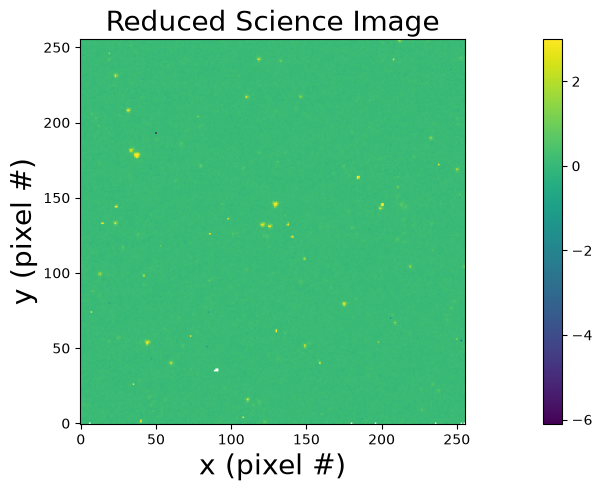

In [5]:
plt.figure('Spitzer IRAC2 Image', figsize = (20, 5))
plt.title('Reduced Science Image', size = 20)
plt.imshow(sci_reduced_image, vmax = 3, origin = 'lower')
plt.colorbar()
plt.xlabel('x (pixel #)', size = 20)
plt.ylabel('y (pixel #)', size = 20)
plt.xlim()
plt.ylim()
plt.show()

# Centering an Aperture and Sky Annulus around an Arbitrary Star

We are going to use the python module photutils to perform aperture extraction over a circle for an arbitrary star. When completing aperture photometry with photutils, you have to define an aperture center and radius. We'll also define an annulus shape around the circular aperture to estimate the error in the future. We'll then plot both on top of our image in the next cell

In [6]:
#Creating parameters for aperture shape and background annulus
center_pixel_x = 219  #center of target location (x) in pixels
center_pixel_y = 104.5  #center of target location (y) in pixels
aperture_radius = 4   #radial width of extraction in pixels
r_in = 7              #inner radius of background annulus in pixels
r_out = 10            #out radius of background annulus in pixels

aperture = CircularAperture((center_pixel_x, center_pixel_y), r=aperture_radius) 
annulus = CircularAnnulus((center_pixel_x, center_pixel_y), r_in, r_out)

# Plot the Extraction Aperture Area and Background Sky Annulus

Play with the values of the extraction radius and annulus to visually learn how much space/area they take up on your reduced science image. You will need this skill to adjust the aperture size and background annulus depending on the telescope and detector used for your final project. The center of an extraction aperture does not need to be an integer value it can also be 100.2, 100.5 etc. It is very rare the center of a source resides exactly within the middle of a pixel.

There are several algorithms avaliable to centroid on a target in python. One is [photutils.centorids](https://photutils.readthedocs.io/en/3.0.0/user_guide/centroids.html).

# Center the Extraction Aperture (Yellow) and Sky Annulus (Red) better by Changing the Extraction Center
update the previous cell and update the plot below

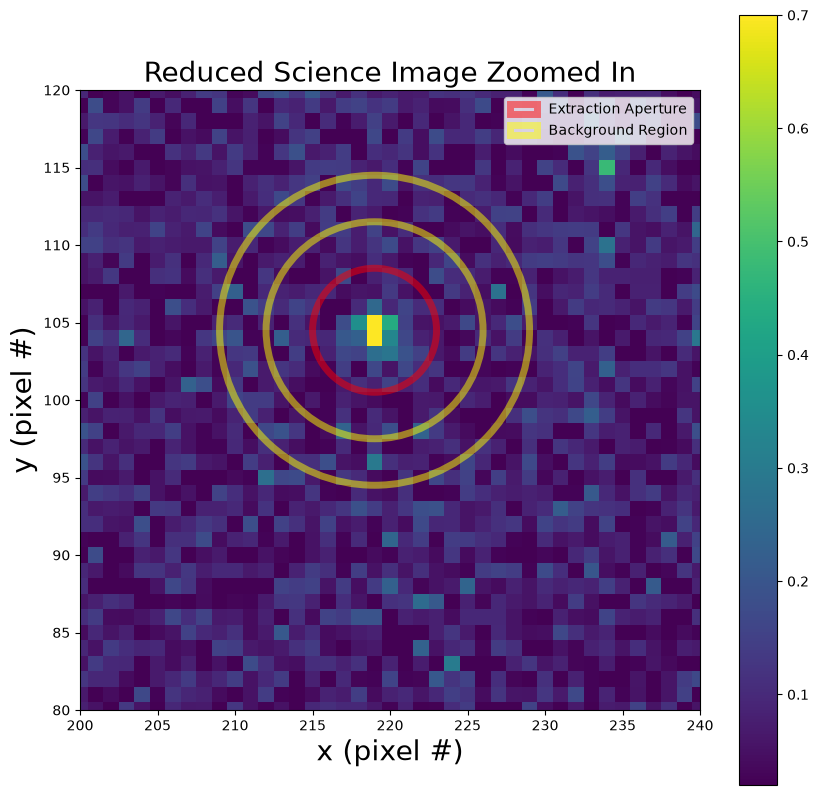

In [7]:
plt.figure('Spitzer IRAC2 Image Zoomed', figsize = (10, 10))
plt.title('Reduced Science Image Zoomed In', size = 20)
plt.imshow(sci_reduced_image, vmin = 0.02, vmax = .7, origin = 'lower')
aperture.plot(color='red', lw=5, alpha=0.5, label = 'Extraction Aperture')
annulus.plot(color='yellow', lw=5, alpha=0.5, label = 'Background Region')
plt.colorbar()
plt.xlabel('x (pixel #)', size = 20)
plt.ylabel('y (pixel #)', size = 20)
plt.xlim([200,240])
plt.ylim([80,120])
plt.legend()
plt.show()

# Complete Aperture Extraction 

To complete aperture extraction on a specific image, we are going to use our aperture class object with the aperture_photometry function from photutils. aperture_photometry can be used to do multiple extractions within a single image, so it returns a table of information but we are only getting infomation for one target here. The table should also return the center x and y values you put in. Even though images are indexed with integer values you are allowed to pick fractional pixel values to center on with the module.

In [8]:
phot_table = aperture_photometry(sci_reduced_image, aperture)
phot_table

id,x_center,y_center,aperture_sum
int64,float64,float64,float64
1,219.0,104.5,9.173599143618581


Here we retrieving the sum of the light within the extraction circle. This is all of the counts/flux contained within the red circle from the previous plot

In [9]:
flux = phot_table['aperture_sum']
flux

9.173599143618581


# Estimating Background and Photometric Error

The background annulus can be used to learn information about two important features. If the background/sky/etc subtraction is not done well there may be some non-zero offset value we have to subtract from the total counts we added up within our science extraction radius. The images we are working with are fully reduced by the Spitzer data pipeline so for now we can assume it was taken care of. Just due to the counting statistics of photons, there is always some scatter inherent to the image background that we can estimate using the standard deviation of the pixels within a background annulus. 

A well behaved background can be modeled by a Poission distribution in the large count limit, which ultimately behaves like a Gaussian distribution. The sigma value of this distribution is related to the scatter you would see in the background of your observations. We are using the scatter in the background to estimate the error per pixel within a science image.   

We are going to use the function apeture_stats to calculate the standard deviation per pixel. We need to multiply this per pixel value by the square root of the number of pixel area used for our science aperture. This can be used to estimate the signal to noise of your photometric point.

# Estimating the Standard Deviation of the Background

we'll use the ApertureStats function on a specific area (the annulus) of the reduced image

In [10]:
bkg_stats = ApertureStats(sci_reduced_image, annulus)

calculate the standard deviation per pixel of the annulus

In [11]:
bkg_sigma = bkg_stats.std
bkg_sigma

np.float64(0.06317856548503256)

get the area (pixels^2) of your science aperture

In [12]:
aperture.area

50.26548245743669

calculate the total error by multiplying the background standard deviation by the square root of the area. We assume all the pixels have the same/similar error, therefore the standard error propagation formula reduces so the total error is proportional to the square root of the number of pixels.

$$\sigma_{total} = \sqrt{\sigma_{\text{pixel}(0)}^2 + \sigma_{\text{pixel}(1)}^2 + \sigma_{\text{pixel}(2)}^2 + \cdots + \sigma_{\text{pixel}(n)}^2}$$

$$\sigma_{total} = \sqrt{N_{\text{pixels}}} \cdot \sigma_{\text{pixel}}$$


In [13]:
flux_err = np.sqrt(aperture.area)*bkg_sigma
flux_err

np.float64(0.4479243667545291)

**calculate the signal to noise of your photometric point in the cell below and print the value**

Check visually against your original plot to make sure the signal-to-noise makes sense. If you have a signal-to-noise of about 100, the star you did aperture photometry on should look about that much brighter than the background of the image.

In [14]:
snr = flux/flux_err
snr

20.480241363260962


# Exploring Curve of Growth for a Target

You have to optimize the radius of the aperture extraction of your science target. To find the best radius value, you need to plot signal-to-noise versus extraction radius to understand when there are diminishing returns by adding too much background signal. Either re-run the previous cells with different radii (and save those values in a new array) for your science aperture or create a for loop that can change aperture radius. Plot signal to noise versus extraction radius for this object. The point spread function of Spitzer is relatively small, you need to center your aperture well and try fractional values (r = 1.5, 1.8, etc) of aperture radii.

In [15]:
#create two new arrays. The first array should hold values of extraction radius, the second should hold values of signal to noise.
#or make a for loop to calculate photometry with different extraction radii.

radii_values = np.arange(.1, 3, .1) #pixels
snr_values = np.ones(radii_values.shape) #make empty values array the same size as the test radii

#moved half a pixel up
center_pixel_x = 220  #center of target location (x) in pixels
center_pixel_y = 104.5  #center of target location (y) in pixels

r_in = 7              #inner radius of background annulus in pixels
r_out = 10            #out radius of background annulus in pixels

for i, radii_val in enumerate(radii_values):

    aperture_test_star = CircularAperture((center_pixel_x, center_pixel_y), r=radii_val) 
    annulus_test_star = CircularAnnulus((center_pixel_x, center_pixel_y), r_in, r_out)

    phot_table_test_star = aperture_photometry(sci_reduced_image, aperture_test_star)
    flux_test = phot_table_test_star['aperture_sum'][0]

    bkg_stats_test_star = ApertureStats(sci_reduced_image, annulus_test_star)
    bkg_sigma_test_star = bkg_stats_test_star.std

    flux_err_test = np.sqrt(aperture_test_star.area)*bkg_sigma_test_star

    snr_values[i] = flux_test/flux_err_test 


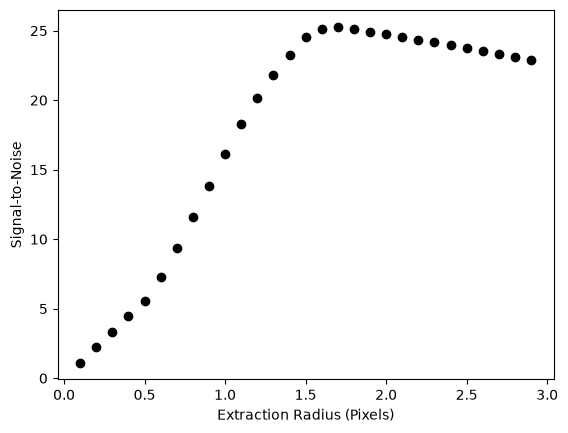

In [16]:
#make a plot here
plt.figure('SNR vs radii')
plt.plot(radii_values, snr_values, 'ko')
plt.xlabel('Extraction Radius (Pixels)')
plt.ylabel('Signal-to-Noise')
plt.show()

# What is the Optimal Radius?

Write below what the optimal radius is for this target and why, and we'll use that radius for our real science target WISE 0855 for the time-series extraction. Discuss if this value is consistent with Spitzer's IRAC2 plate scale and/or diffraction limit given the telescope's diameter.

In [17]:
#Table 2.1 of the IRAC handbook
#https://irsa.ipac.caltech.edu/data/SPITZER/docs/irac/iracinstrumenthandbook/5/
#1.213 arcseconds per pixel

D = 0.85         #meters
lam = 4.5 * 1e-6 #meters 
irac2_plate_scale = 1.213 #arcseconds

diffraction_limit = (1.22 * lam/D) #radians
diffraction_limit *= 206265        #arcseconds

print('Diffraction Limit of Spitzer IRAC 2 Channel:', diffraction_limit)
print('Spitzer IRAC2 plate scale:', irac2_plate_scale)

Diffraction Limit of Spitzer IRAC 2 Channel: 1.3322292352941176
Spitzer IRAC2 plate scale: 1.213


In general the extraction radius needs to be bigger than the diffraction limit or PSF size of your source. If it is less than the diffraction limit, you are not enclosing a significant porition of the light for your source. Spitzer is spatially undersampled, you typically want 2 pixels to cover the physical size of the diffraction limit. In the case of IRAC is half what is ideal.

# Finding WISE 0855 in a Single Spitzer Image

WISE 0855 is challenging to find outright so I'm providing an image subset of where the object is. Using a new or previous plot, look for a similar pattern of stars in the full field of view of the data. You will need to adjust the x and y limits of imshow to locate the center x-value and y-value of the object. You can also do this in fits viewer like DS9

<div>
<img src="wise0855.png" width="400"/>
</div>

# Isolate WISE 0855 within a Python Plot

I looked for a regular pattern of three stars within the image. I generally have to flip back and forth between a few images.

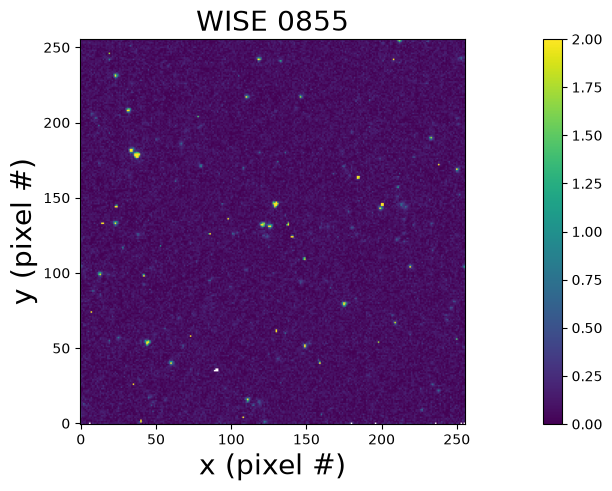

In [18]:
plt.figure('Spitzer IRAC2 - WISE 0855', figsize = (20, 5))
plt.title('WISE 0855', size = 20)
plt.imshow(sci_reduced_image, vmin = 0, vmax = 2, origin = 'lower')
plt.colorbar()
plt.xlabel('x (pixel #)', size = 20)
plt.ylabel('y (pixel #)', size = 20)
plt.xlim()
plt.ylim()
plt.show()

# Create and Center an Extraction Radius and Annulus for WISE 0855

In [19]:
#put aperture and annulus information here, you need to update the center locations for WISE 0855

#Creating parameters for aperture shape and background annulus
center_pixel_x = 23.5 #center of target location (x) in pixels
center_pixel_y = 231.3  #center of target location (y) in pixels
aperture_radius = 1.5   #radial width of extraction in pixels
r_in = 7              #inner radius of background annulus in pixels
r_out = 10            #out radius of background annulus in pixels

aperture = CircularAperture((center_pixel_x, center_pixel_y), r=aperture_radius) 
annulus = CircularAnnulus((center_pixel_x, center_pixel_y), r_in, r_out)

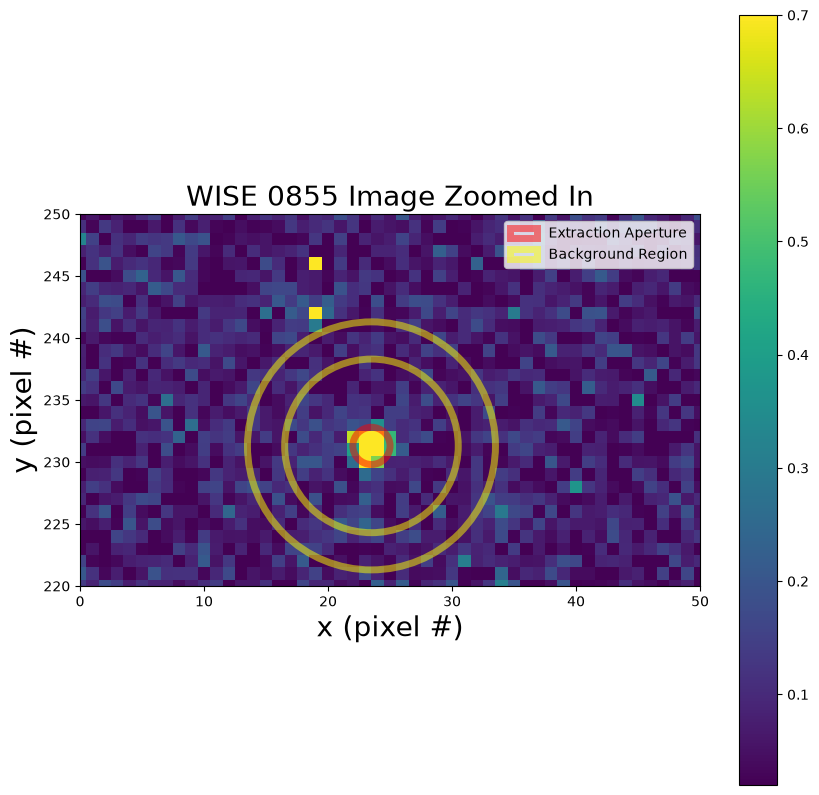

In [20]:
#create plot of WISE 0855 subset and the apertures you made
plt.figure('WISE 0855 Image Zoomed', figsize = (10, 10))
plt.title('WISE 0855 Image Zoomed In', size = 20)
plt.imshow(sci_reduced_image, vmin = 0.02, vmax = .7, origin = 'lower')
aperture.plot(color='red', lw=5, alpha=0.5, label = 'Extraction Aperture')
annulus.plot(color='yellow', lw=5, alpha=0.5, label = 'Background Region')
plt.colorbar()
plt.xlabel('x (pixel #)', size = 20)
plt.ylabel('y (pixel #)', size = 20)
plt.xlim([0,50])
plt.ylim([220,250])
plt.legend()
plt.show()

# Calculate the Flux of WISE 0855 and the Error for a Single Image

In [21]:
aperture_wise0855 = CircularAperture((center_pixel_x, center_pixel_y), r=radii_val) 
annulus_wise0855 = CircularAnnulus((center_pixel_x, center_pixel_y), r_in, r_out)

phot_table_wise0855 = aperture_photometry(sci_reduced_image, aperture_wise0855)
flux_wise0855 = phot_table_wise0855['aperture_sum'][0]

bkg_stats_wise0855 = ApertureStats(sci_reduced_image, annulus_wise0855)
bkg_sigma_wise0855 = bkg_stats_wise0855.std

flux_err_wise0855 = np.sqrt(aperture_wise0855.area)*bkg_sigma_wise0855


In [22]:
print(flux_wise0855)

14.806013413532629


In [23]:
print(flux_err_wise0855)

0.2883191034210519


# Complete Aperture Extraction for all Images

We'll start by calling in all of the filenames of our Spitzer data. After calling them in, we reorder them by filename. You may not always have to do the reordering.

In [24]:
files = glob.glob('data/*')
files = np.array(files)

file_nos = np.zeros(len(files))

for i, filename in enumerate(files):
    
    file_nos[i] = float(filename.split('_')[3])
    
order = np.argsort(file_nos)
files = files[order]

In [25]:
files

array(['data/SPITZER_I2_52667904_0001_0000_2_cbcd.fits',
       'data/SPITZER_I2_52667904_0002_0000_2_cbcd.fits',
       'data/SPITZER_I2_52667904_0003_0000_2_cbcd.fits',
       'data/SPITZER_I2_52667904_0004_0000_2_cbcd.fits',
       'data/SPITZER_I2_52667904_0005_0000_2_cbcd.fits',
       'data/SPITZER_I2_52667904_0006_0000_2_cbcd.fits',
       'data/SPITZER_I2_52667904_0007_0000_2_cbcd.fits',
       'data/SPITZER_I2_52667904_0008_0000_2_cbcd.fits',
       'data/SPITZER_I2_52667904_0009_0000_2_cbcd.fits',
       'data/SPITZER_I2_52667904_0010_0000_2_cbcd.fits',
       'data/SPITZER_I2_52667904_0011_0000_2_cbcd.fits',
       'data/SPITZER_I2_52667904_0012_0000_2_cbcd.fits',
       'data/SPITZER_I2_52667904_0013_0000_2_cbcd.fits',
       'data/SPITZER_I2_52667904_0014_0000_2_cbcd.fits',
       'data/SPITZER_I2_52667904_0015_0000_2_cbcd.fits',
       'data/SPITZER_I2_52667904_0016_0000_2_cbcd.fits',
       'data/SPITZER_I2_52667904_0017_0000_2_cbcd.fits',
       'data/SPITZER_I2_5266790

# Data Analysis over a For Loop
You do not want to manually set parameters for 400 separate images. For this program WISE 0855 is stationary on the detector, so you can apply the same extraction area and annulus to all images. Create a for loop that can:

1) Read in the data for the relevant file
2) Apply aperture extraction
3) Estimate the error from a background annlus
4) Save both the extracted flux and error from each image

You should be saving data in two separate arrays: fluxes and flux_errors. (or whatever name you wish)

In [26]:
fluxes = np.zeros(files.shape)
flux_errors = np.zeros(files.shape)
image_nos = np.zeros(files.shape)

for i, file in enumerate(files):

    data = fits.getdata(file)
    
    phot_table_wise0855 = aperture_photometry(data, aperture_wise0855)
    flux_wise0855 = phot_table_wise0855['aperture_sum'][0]

    bkg_stats_wise0855 = ApertureStats(data, annulus_wise0855)
    bkg_sigma_wise0855 = bkg_stats_wise0855.std

    flux_err_wise0855 = np.sqrt(aperture_wise0855.area)*bkg_sigma_wise0855

    fluxes[i] = flux_wise0855
    flux_errors[i] = flux_err_wise0855
    image_nos[i] = i

# Plot WISE 0855's Flux Over Time

Plot flux of WISE 0855 vs time or just image number. Compare your data to Figure 1 of Esplin 2016 (https://ui.adsabs.harvard.edu/abs/2016ApJ...832...58E/abstract)

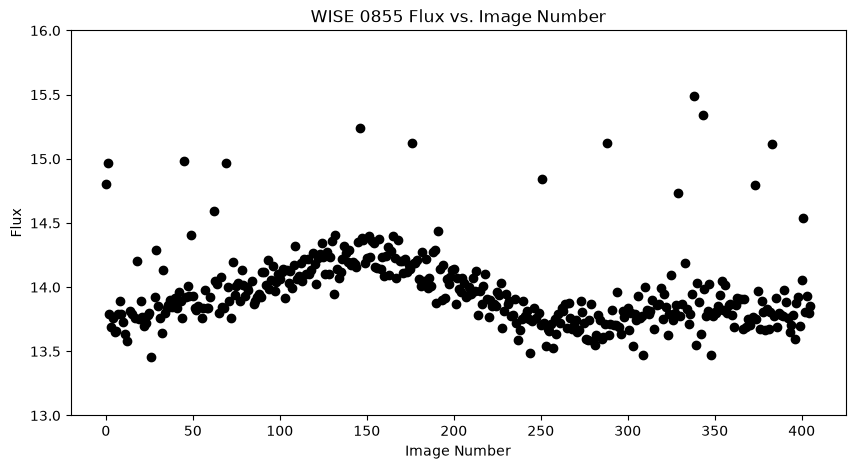

In [27]:
plt.figure('WISE 0855 Flux vs. Image Number', figsize = (10, 5))
plt.title('WISE 0855 Flux vs. Image Number')
plt.plot(image_nos,fluxes, 'ko')
plt.ylim([13, 16])
plt.ylabel('Flux')
plt.xlabel('Image Number')
plt.show()

# Plot WISE 0855's Flux Over Time with Error Bars

Create the same plot but instead of plt.plot() use plt.errorbar() https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.errorbar.html to display the error on top of the data

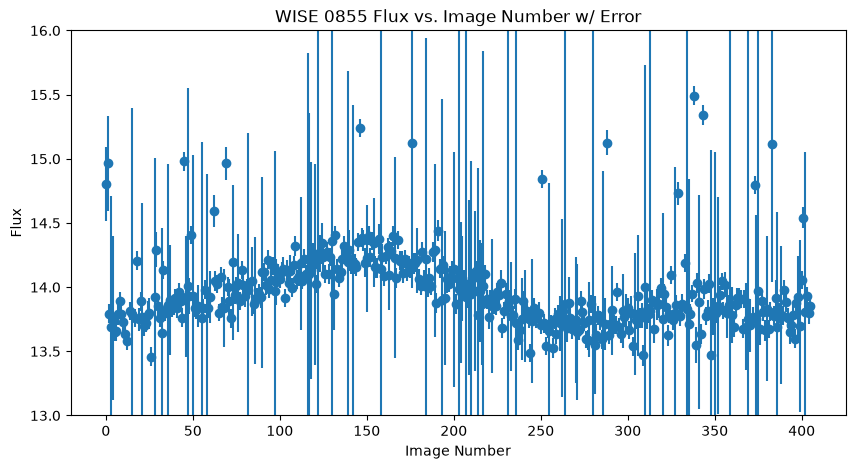

In [28]:
plt.figure('WISE 0855 Flux vs. Image Number w/ Error', figsize = (10, 5))
plt.title('WISE 0855 Flux vs. Image Number w/ Error')
plt.errorbar(image_nos, y= fluxes, yerr = flux_errors, linestyle = 'None', marker = 'o')
plt.ylim([13, 16])
plt.ylabel('Flux')
plt.xlabel('Image Number')
plt.show()

# Describe the Changes in the Time-Series Photometry

-How does the brightness of WISE 0855 change
-What are some of driving mechanisms of the brightness changes on this object based on the paper

The behavior is a bit periodic. The brightness variations are much larger than the errorbars. 

# Save Your Data Arrays for Later

Learn how to save your extracted fluxes to your own computer. It is good practice to use separate notebooks for data reduction/extraction and scientific interpretation. For smaller projects, numpy.save can be a good option. Read the documentation here: https://numpy.org/doc/2.2/reference/generated/numpy.save.html

Save the array for fluxes.
Then save the array for flux errors.

In [29]:
np.save('wise0855_flux', fluxes)
np.save('wise0855_flux_errs',flux_errors)

# Load Save Files

To make sure you understand how numpy.save works or however you decided to save your data. Reload that information in the cell below. You can load numpy save files with numpy.load()

In [30]:
fluxes_load = np.load('wise0855_fluxes.npy')
flux_errors_load = np.load('wise0855_flux_errors.npy')